# 08 — Visualize experimental results from CSV files

**Goal:** Turn the already completed seed × scale experiments into readable figures, without retraining.

We compare three conditions:

1. **Ordinary scaling** — complex input coordinates multiplied by $\alpha$, original weights and SGD learning rate unchanged.
2. **Inverse initialization** — complex input coordinates multiplied by $\alpha$ and first-layer complex weights divided by $\alpha$. Initial functions match, but SGD dynamics need not.
3. **Compensated SGD** — inverse initialization plus complex-column learning rate $\eta/\alpha^2$. Effective SGD trajectories should match the $\alpha=1$ reference.

**Main metric:** `complex_reliance` is the fraction of four *out-of-distribution* contradictory probes on which the model agrees with the complex rule. It is **not** in-distribution classification accuracy.

**Run order:** Run the experiment runner first to create `results/all_runs.csv` and `results/final_summary.csv`, then run this notebook from top to bottom. The notebook also accepts CSV files placed next to the notebook or in its parent folder.

## 1. Load dependencies and find CSVs

We use only `pandas`, `numpy`, and `matplotlib`. The lookup checks `results/`, the notebook directory, and its parent, so you can use your uploaded CSVs without modifying their contents. The `assert` checks catch missing or malformed input early.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({'figure.figsize': (9, 5), 'axes.grid': True, 'grid.alpha': 0.25})

ROOT = Path.cwd()
SEARCH_DIRS = [ROOT / 'results', ROOT, ROOT.parent / 'results', ROOT.parent]

def locate(filename):
    for folder in SEARCH_DIRS:
        path = folder / filename
        if path.is_file():
            return path
    raise FileNotFoundError(f"Cannot find {filename}. Checked: {SEARCH_DIRS}")

hist_path = locate('all_runs.csv')
summary_path = locate('final_summary.csv')
history = pd.read_csv(hist_path)
final = pd.read_csv(summary_path)
required = {'experiment', 'seed', 'alpha', 'step', 'loss', 'accuracy', 'complex_reliance'}
assert required.issubset(history.columns), required - set(history.columns)
assert required.issubset(final.columns), required - set(final.columns)
print('Training history:', hist_path, '| rows:', len(history))
print('Final summary:', summary_path, '| rows:', len(final))
print('Conditions:', sorted(final.experiment.unique()))
print('Seeds:', sorted(final.seed.unique()))
print('Scales:', sorted(final.alpha.unique()))

Training history: C:\Users\ESHAAN\Downloads\simplicity_bias_research\simplicity_bias_research\simplicity_bias_with_counterfactual_metrics\.validation\notebook_runs\results\all_runs.csv | rows: 1890
Final summary: C:\Users\ESHAAN\Downloads\simplicity_bias_research\simplicity_bias_research\simplicity_bias_with_counterfactual_metrics\.validation\notebook_runs\results\final_summary.csv | rows: 90
Conditions: ['compensated_sgd', 'inverse_init', 'ordinary']
Seeds: [np.int64(42), np.int64(43), np.int64(44), np.int64(45), np.int64(46)]
Scales: [np.float64(0.1), np.float64(0.5), np.float64(1.0), np.float64(2.0), np.float64(5.0), np.float64(10.0)]


## 2. Validate the experiment grid

Every `(experiment, seed, alpha)` should appear exactly once in `final_summary.csv`. A missing run or duplicate would bias the aggregated graphs. The training-history file may have multiple rows per run because it records successive SGD steps.

In [2]:
conditions = ['ordinary', 'inverse_init', 'compensated_sgd']
assert set(conditions).issubset(set(final.experiment.unique())), 'Missing experimental condition'
assert not final.duplicated(['experiment', 'seed', 'alpha']).any(), 'Duplicate final run'
expected_runs = pd.MultiIndex.from_product(
    [conditions, sorted(final.seed.unique()), sorted(final.alpha.unique())],
    names=['experiment', 'seed', 'alpha'])
actual_runs = pd.MultiIndex.from_frame(final[['experiment', 'seed', 'alpha']])
assert set(actual_runs) == set(expected_runs), 'Incomplete condition × seed × scale grid'
assert not history.duplicated(['experiment', 'seed', 'alpha', 'step']).any(), 'Duplicate history checkpoint'
assert set(pd.MultiIndex.from_frame(history[['experiment', 'seed', 'alpha']])) == set(actual_runs), 'History/final grids differ'
counts = final.groupby(['experiment', 'alpha']).seed.nunique().unstack(0)
print('Number of seeds at each scale and condition:')
print(counts.to_string())
print('All runs have 100% final accuracy:', bool((final.accuracy == 1).all()))

Number of seeds at each scale and condition:
experiment  compensated_sgd  inverse_init  ordinary
alpha                                              
0.1                       5             5         5
0.5                       5             5         5
1.0                       5             5         5
2.0                       5             5         5
5.0                       5             5         5
10.0                      5             5         5
All runs have 100% final accuracy: True


## 3. Shared plotting helper

We aggregate **across seeds** for each alpha. The line shows the mean; the shaded region is **mean ± one standard deviation**, clipped to `[0, 1]` for all metrics bounded to [0, 1]. This is descriptive seed variability, **not** a confidence interval. The same aggregation is used throughout to keep comparisons fair.

Scale axes use logarithmic spacing, with tick labels at the tested alpha values.

In [3]:
LABELS = {'ordinary': 'Ordinary scaling', 'inverse_init': 'Inverse initialization', 'compensated_sgd': 'Compensated SGD'}
COLORS = {'ordinary': 'tab:blue', 'inverse_init': 'tab:orange', 'compensated_sgd': 'tab:green'}
FIGURES = ROOT / 'results' / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
SAVE_FIGURES = True

def finish(name):
    plt.tight_layout()
    if SAVE_FIGURES:
        plt.savefig(FIGURES / f'{name}.png', dpi=170, bbox_inches='tight')
    plt.show()

def mean_sd_plot(ax, frame, metric, condition, label=None):
    group = frame[frame.experiment == condition].groupby('alpha')[metric].agg(['mean', 'std']).sort_index()
    x = group.index.to_numpy(dtype=float)
    mean = group['mean'].to_numpy(dtype=float)
    sd = group['std'].fillna(0).to_numpy(dtype=float)
    color = COLORS[condition]
    ax.plot(x, mean, 'o-', label=label or LABELS[condition], color=color)
    lower, upper = mean - sd, mean + sd
    if metric in ('complex_reliance', 'accuracy', 'simple_flip_rate', 'complex_flip_rate',
                  'simple_probability_change', 'complex_probability_change'):
        lower, upper = np.clip(lower, 0, 1), np.clip(upper, 0, 1)
    ax.fill_between(x, lower, upper, color=color, alpha=0.15)
    ax.set_xlabel('Complex feature scale α')
    scales = sorted(frame.alpha.unique())
    ax.set_xscale('log')
    ax.set_xticks(scales, labels=[f'{a:g}' for a in scales])
    ax.grid(True, alpha=0.25)
    return group


## Ordinary scaling: individual experiment graphs

This is the uncontrolled experiment: changing alpha affects the input magnitudes and can change the initial network function.

**Graph A:** final complex conflict reliance versus scale, showing seed variability. **Graph B:** final training loss versus scale. **Graph C:** reliance over training steps at selected scales, averaged across seeds. Remember that conflict reliance is an OOD diagnostic.

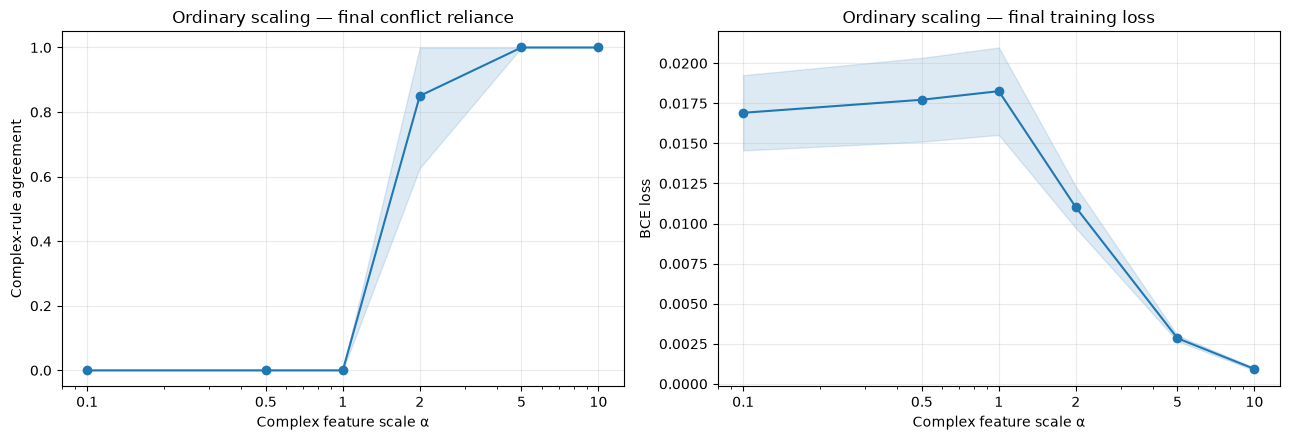

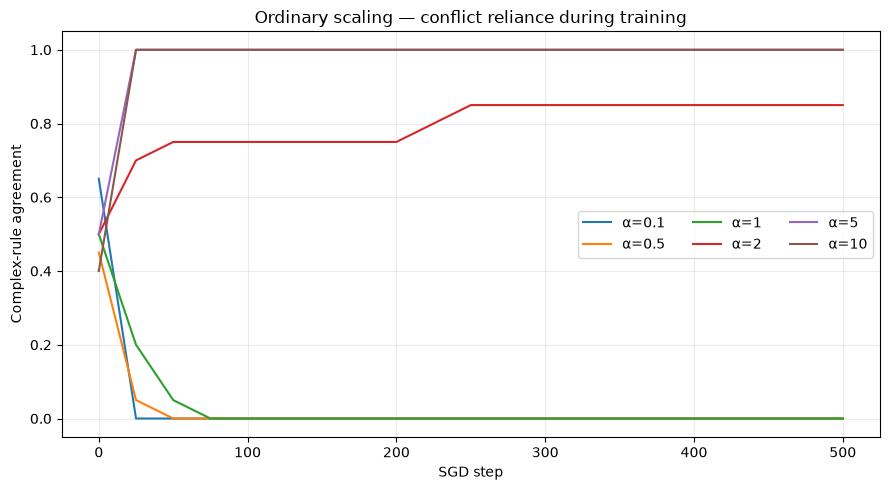

In [4]:
condition = 'ordinary'
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
mean_sd_plot(axes[0], final, 'complex_reliance', condition)
axes[0].set(title=f'{LABELS[condition]} — final conflict reliance', ylabel='Complex-rule agreement', ylim=(-0.05, 1.05))
mean_sd_plot(axes[1], final, 'loss', condition)
axes[1].set(title=f'{LABELS[condition]} — final training loss', ylabel='BCE loss')
finish('ordinary_final')

fig, ax = plt.subplots(figsize=(9, 5))
subset = history[history.experiment == condition]
for a in sorted(subset.alpha.unique()):
    trajectory = subset[subset.alpha == a].groupby('step').complex_reliance.mean().sort_index()
    ax.plot(trajectory.index, trajectory.values, label=f'α={a:g}')
ax.set(title=f'{LABELS[condition]} — conflict reliance during training', xlabel='SGD step', ylabel='Complex-rule agreement', ylim=(-0.05, 1.05))
ax.legend(ncol=3)
finish('ordinary_reliance_trajectories')

## Inverse initialization: individual experiment graphs

Initial functions match the alpha=1 reference, but the effective complex-feature SGD update scales as alpha squared.

**Graph A:** final complex conflict reliance versus scale, showing seed variability. **Graph B:** final training loss versus scale. **Graph C:** reliance over training steps at selected scales, averaged across seeds. Remember that conflict reliance is an OOD diagnostic.

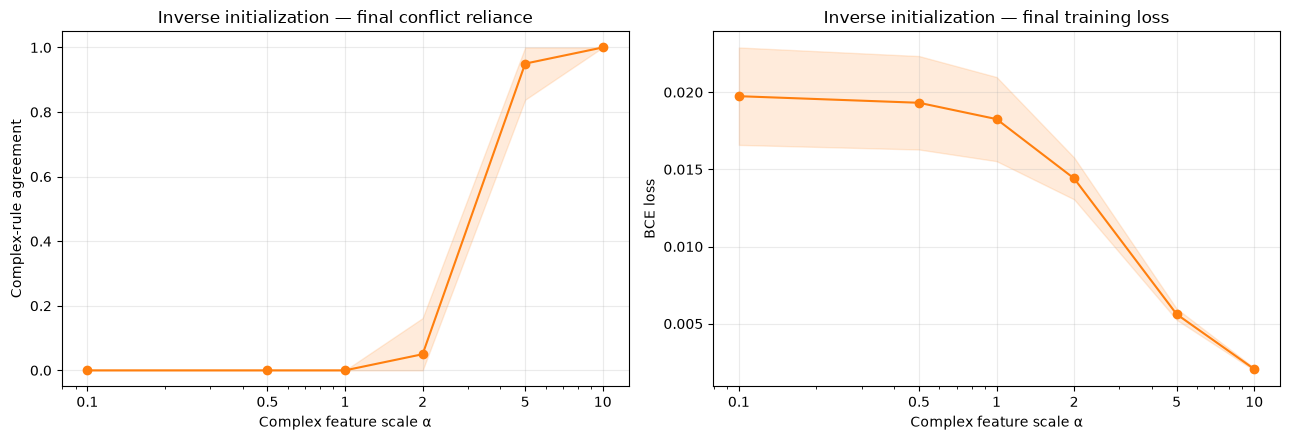

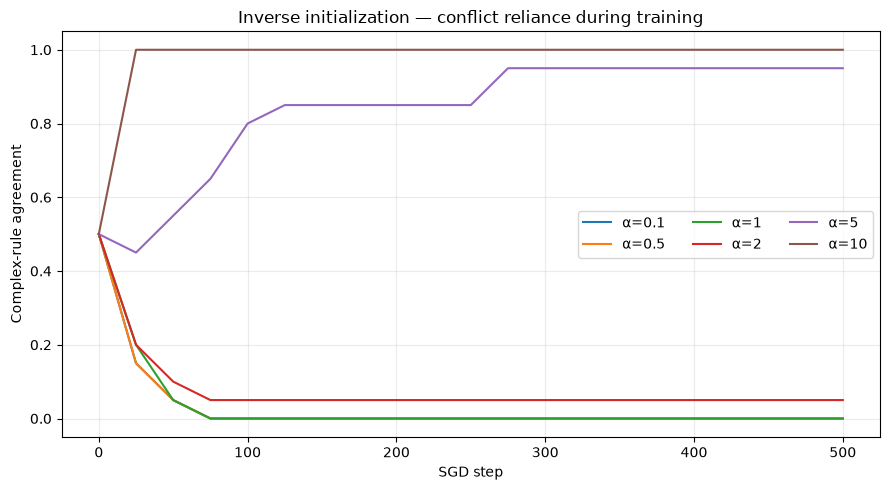

In [5]:
condition = 'inverse_init'
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
mean_sd_plot(axes[0], final, 'complex_reliance', condition)
axes[0].set(title=f'{LABELS[condition]} — final conflict reliance', ylabel='Complex-rule agreement', ylim=(-0.05, 1.05))
mean_sd_plot(axes[1], final, 'loss', condition)
axes[1].set(title=f'{LABELS[condition]} — final training loss', ylabel='BCE loss')
finish('inverse_init_final')

fig, ax = plt.subplots(figsize=(9, 5))
subset = history[history.experiment == condition]
for a in sorted(subset.alpha.unique()):
    trajectory = subset[subset.alpha == a].groupby('step').complex_reliance.mean().sort_index()
    ax.plot(trajectory.index, trajectory.values, label=f'α={a:g}')
ax.set(title=f'{LABELS[condition]} — conflict reliance during training', xlabel='SGD step', ylabel='Complex-rule agreement', ylim=(-0.05, 1.05))
ax.legend(ncol=3)
finish('inverse_init_reliance_trajectories')

## Compensated SGD: individual experiment graphs

Both initial functions and effective SGD update sizes are matched; we expect reference-equivalent trajectories, up to numerical precision.

**Graph A:** final complex conflict reliance versus scale, showing seed variability. **Graph B:** final training loss versus scale. **Graph C:** reliance over training steps at selected scales, averaged across seeds. Remember that conflict reliance is an OOD diagnostic.

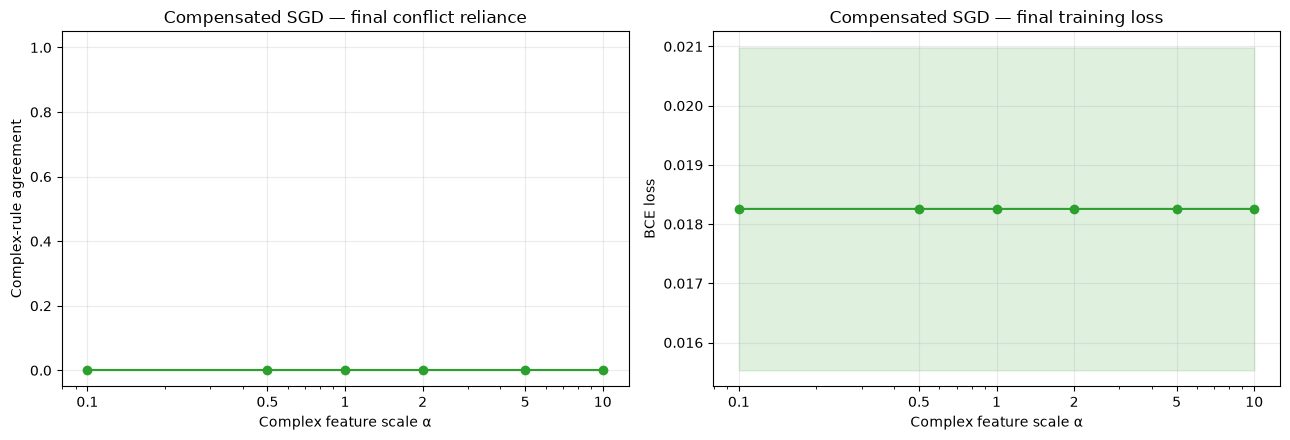

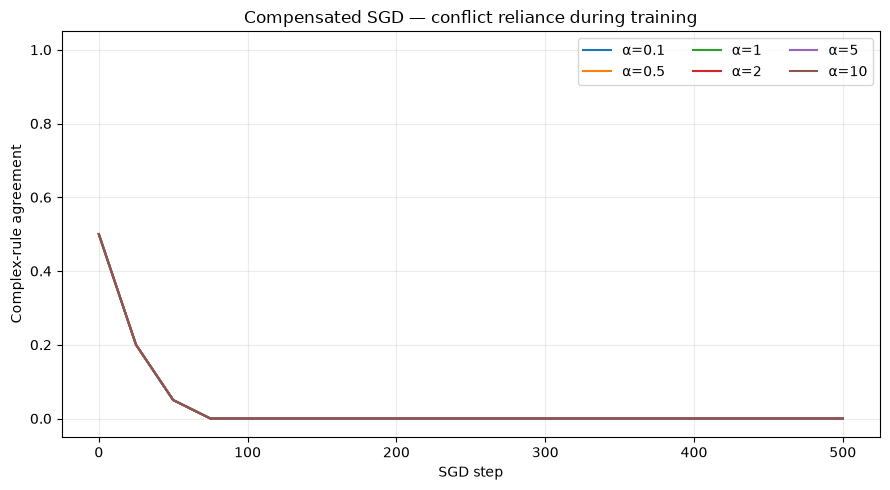

In [6]:
condition = 'compensated_sgd'
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
mean_sd_plot(axes[0], final, 'complex_reliance', condition)
axes[0].set(title=f'{LABELS[condition]} — final conflict reliance', ylabel='Complex-rule agreement', ylim=(-0.05, 1.05))
mean_sd_plot(axes[1], final, 'loss', condition)
axes[1].set(title=f'{LABELS[condition]} — final training loss', ylabel='BCE loss')
finish('compensated_final')

fig, ax = plt.subplots(figsize=(9, 5))
subset = history[history.experiment == condition]
for a in sorted(subset.alpha.unique()):
    trajectory = subset[subset.alpha == a].groupby('step').complex_reliance.mean().sort_index()
    ax.plot(trajectory.index, trajectory.values, label=f'α={a:g}')
ax.set(title=f'{LABELS[condition]} — conflict reliance during training', xlabel='SGD step', ylabel='Complex-rule agreement', ylim=(-0.05, 1.05))
ax.legend(ncol=3)
finish('compensated_reliance_trajectories')

## 7. All three conditions — final results side by side

These figures answer the main research question directly: **does scaling change complex-rule agreement, and which controls remove that effect?** The next plot compares loss. Final training accuracy is shown separately because perfect accuracy can hide very different learned rules.

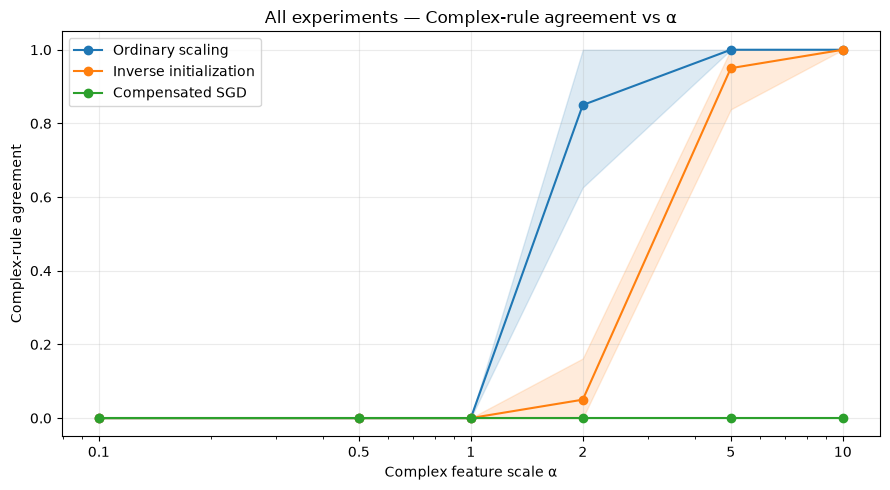

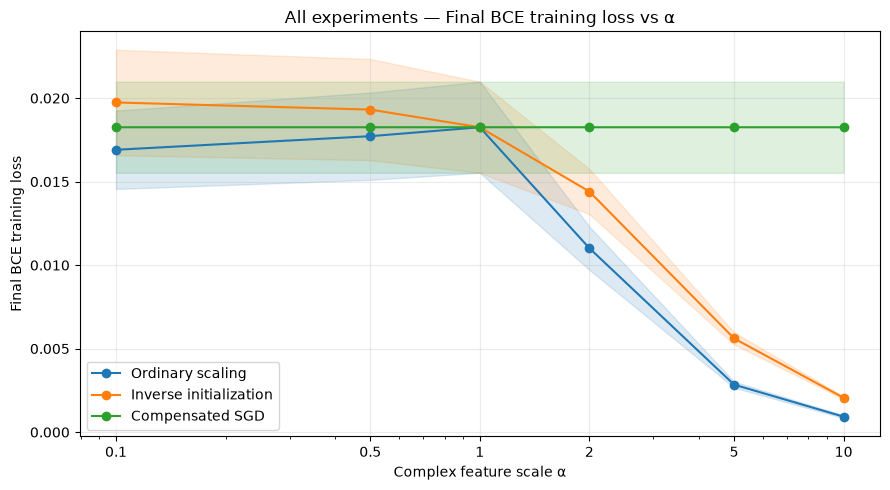

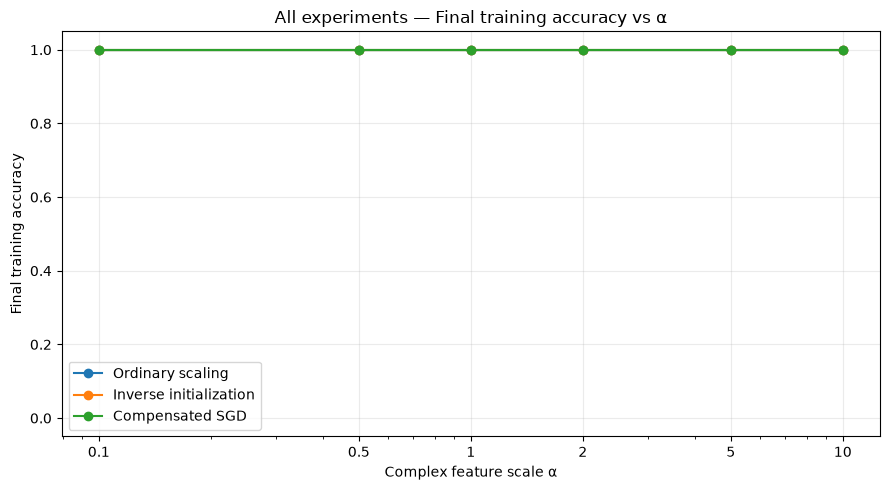

In [7]:
for metric, ylabel, name in [
    ('complex_reliance', 'Complex-rule agreement', 'combined_final_reliance'),
    ('loss', 'Final BCE training loss', 'combined_final_loss'),
    ('accuracy', 'Final training accuracy', 'combined_final_accuracy')
]:
    fig, ax = plt.subplots(figsize=(9, 5))
    for condition in conditions:
        mean_sd_plot(ax, final, metric, condition)
    ax.set(title=f'All experiments — {ylabel} vs α', ylabel=ylabel)
    if metric in ('complex_reliance', 'accuracy'):
        ax.set_ylim(-0.05, 1.05)
    ax.legend()
    finish(name)

## 8. All three conditions — loss curves over SGD steps

To avoid a cluttered plot, choose a single alpha (default `5.0`) and compare the three conditions over time. Curves are averaged across seeds; each run contributes one value at every recorded step. Try `ALPHA_TO_PLOT = 2.0` or `10.0` to examine different regimes.

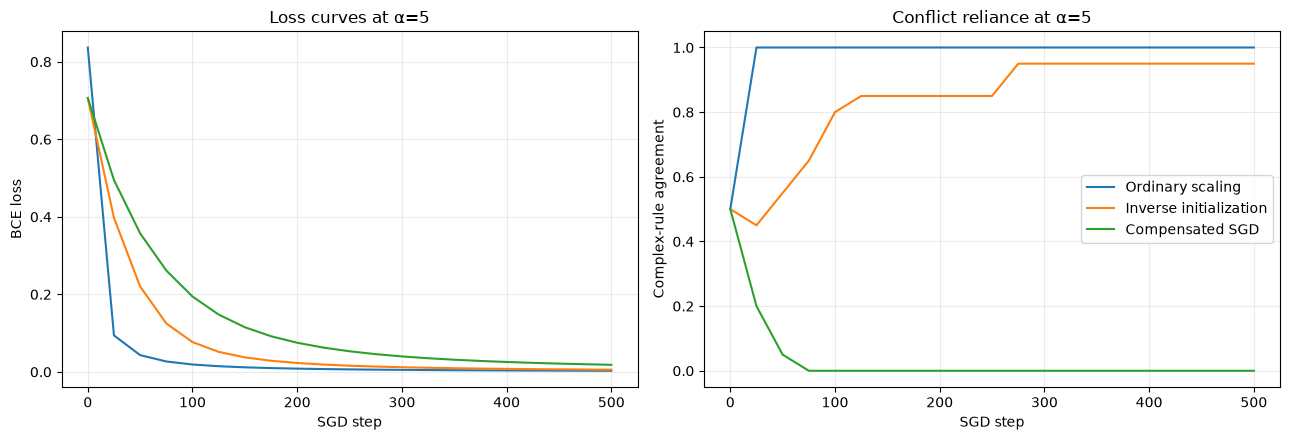

In [8]:
ALPHA_TO_PLOT = 5.0
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for condition in conditions:
    d = history[(history.experiment == condition) & (np.isclose(history.alpha, ALPHA_TO_PLOT))]
    assert not d.empty, f'Missing alpha={ALPHA_TO_PLOT} for {condition}'
    curves = d.groupby('step')[['loss', 'complex_reliance']].mean().sort_index()
    axes[0].plot(curves.index, curves.loss, label=LABELS[condition], color=COLORS[condition])
    axes[1].plot(curves.index, curves.complex_reliance, label=LABELS[condition], color=COLORS[condition])
axes[0].set(title=f'Loss curves at α={ALPHA_TO_PLOT:g}', xlabel='SGD step', ylabel='BCE loss')
axes[1].set(title=f'Conflict reliance at α={ALPHA_TO_PLOT:g}', xlabel='SGD step', ylabel='Complex-rule agreement', ylim=(-0.05, 1.05))
axes[1].legend()
finish(f'combined_training_curves_alpha_{ALPHA_TO_PLOT:g}')

## 9. Control verification: initialization errors and final functional equivalence

Inverse initialization predicts identical initial pre-activations/logits and the gradient identity $g_{c,\alpha}=\alpha g_{c,1}$. These checks should be close to floating-point precision, **not** necessarily exactly zero.

Compensated SGD predicts the **same final logits** as the alpha=1 reference (up to numerical precision). We plot the maximum absolute final-logit discrepancy. A small error provides stronger evidence than equal conflict-reliance scores alone.

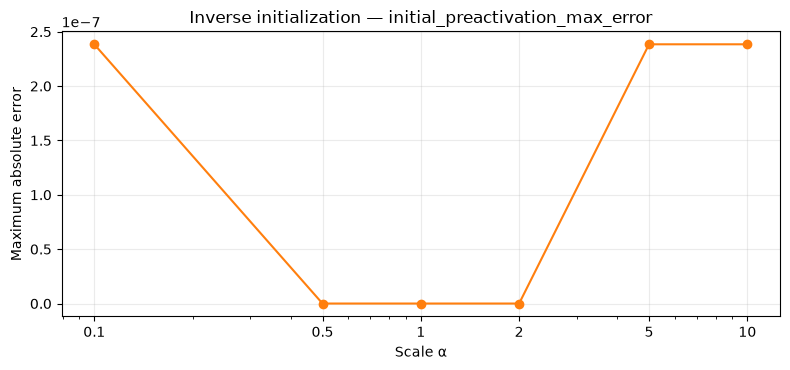

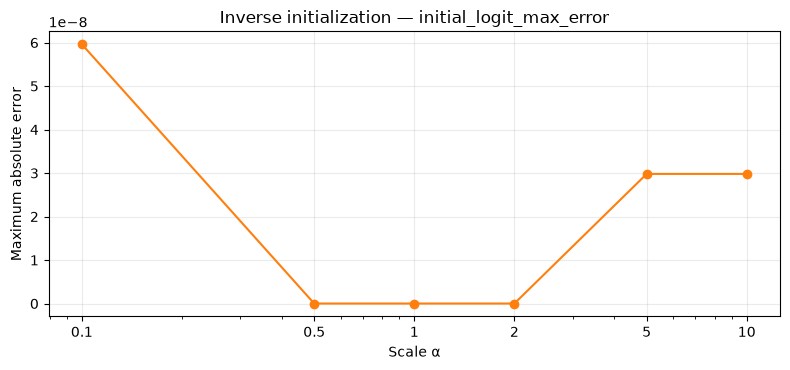

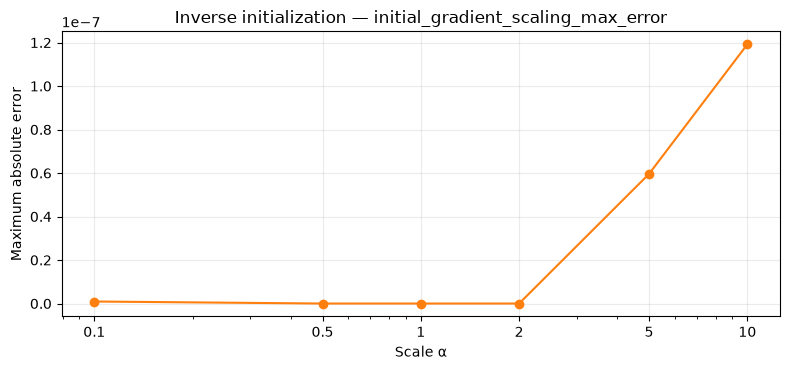

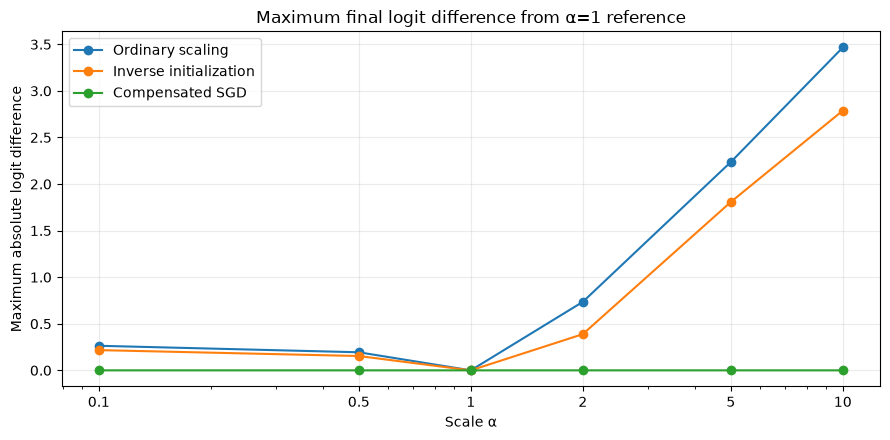

In [9]:
check_cols = ['initial_preactivation_max_error', 'initial_logit_max_error', 'initial_gradient_scaling_max_error']
for col in check_cols:
    if col in final.columns:
        d = final[final.experiment == 'inverse_init'].groupby('alpha')[col].max()
        fig, ax = plt.subplots(figsize=(8, 3.8))
        ax.plot(d.index, d.values, 'o-', color='tab:orange')
        ax.set(title=f'Inverse initialization — {col}', xlabel='Scale α', ylabel='Maximum absolute error')
        ax.set_xscale('log')
        ax.set_xticks(sorted(final.alpha.unique()), labels=[f'{a:g}' for a in sorted(final.alpha.unique())])
        finish(col)

col = 'final_logit_max_error_vs_alpha1_reference'
if col in final.columns:
    fig, ax = plt.subplots(figsize=(9, 4.5))
    for condition in conditions:
        d = final[final.experiment == condition].groupby('alpha')[col].max().sort_index()
        ax.plot(d.index, d.values, 'o-', label=LABELS[condition], color=COLORS[condition])
    ax.set(title='Maximum final logit difference from α=1 reference', xlabel='Scale α', ylabel='Maximum absolute logit difference')
    ax.set_xscale('log')
    ax.set_xticks(sorted(final.alpha.unique()), labels=[f'{a:g}' for a in sorted(final.alpha.unique())])
    ax.legend()
    finish('combined_final_logit_error')

## 10. Counterfactual feature sensitivity — each experiment and combined

The experiment runner now records four additional metrics at every saved step:

- `simple_flip_rate`: proportion of predictions changing after flipping only the simple feature.
- `complex_flip_rate`: proportion changing after flipping one complex coordinate (reverses the complex rule).
- `simple_probability_change`: mean absolute change in sigmoid probability after the simple flip.
- `complex_probability_change`: corresponding mean absolute probability change for the complex flip.

The interventions deliberately contradict the original feature agreement, so they are **out-of-distribution diagnostics**. Hard flips are coarse; probability changes capture shifts that do not cross the classification threshold. These are metrics, not additional training controls. The same measurements apply to ordinary, inverse-initialized and compensated-SGD runs.

**Important:** Old CSV files do not contain these columns. Re-run `python run_all_experiments.py` to regenerate them. The cell below explains this if the columns are missing.

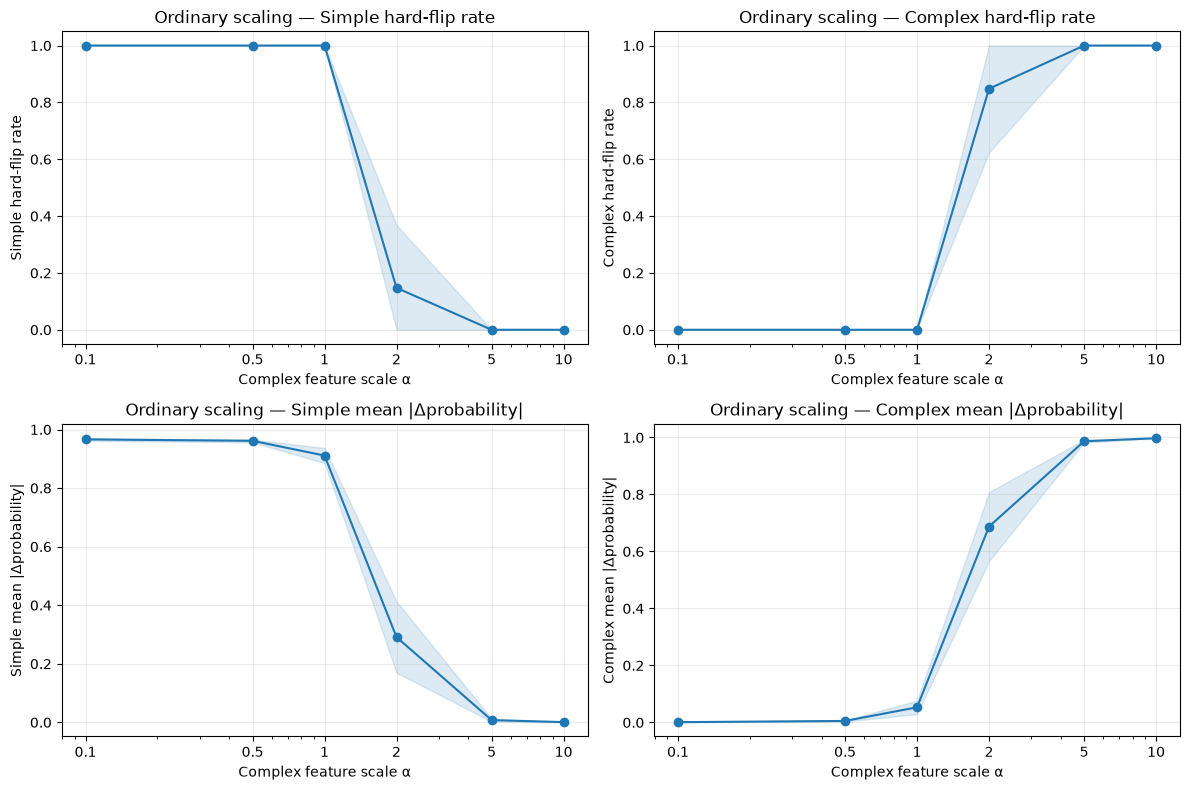

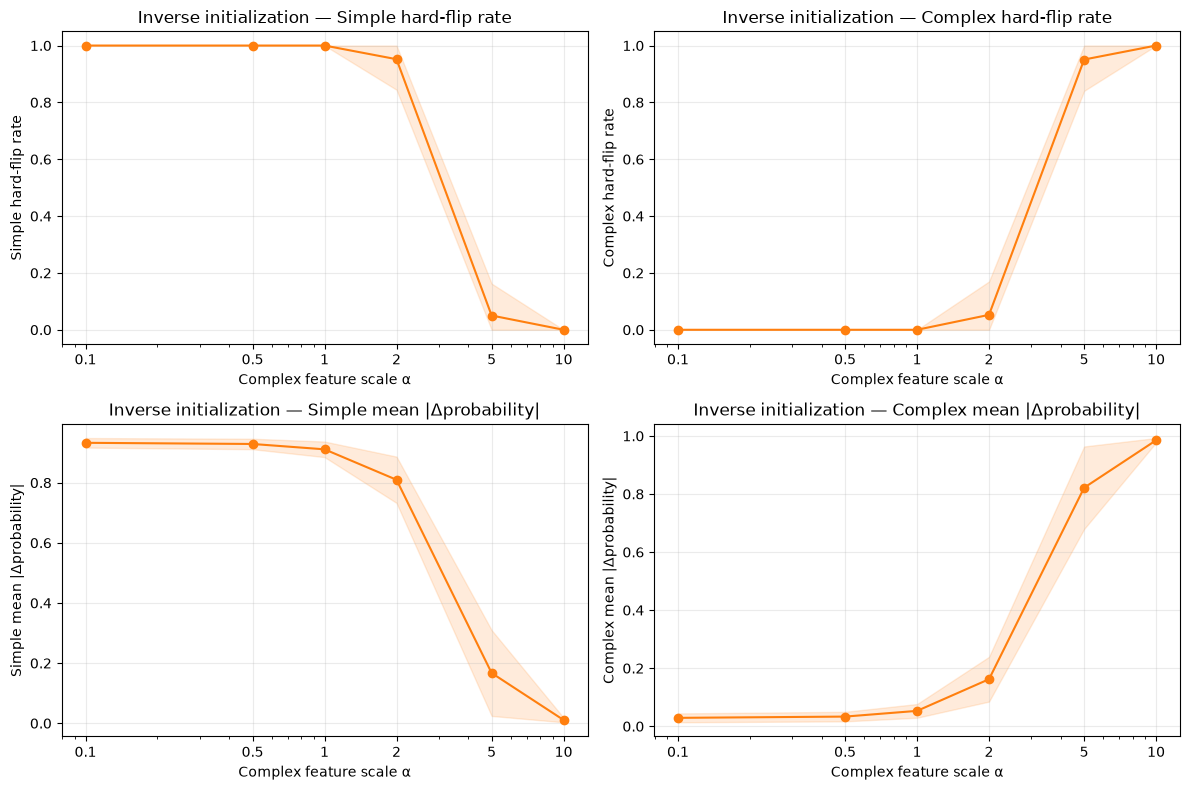

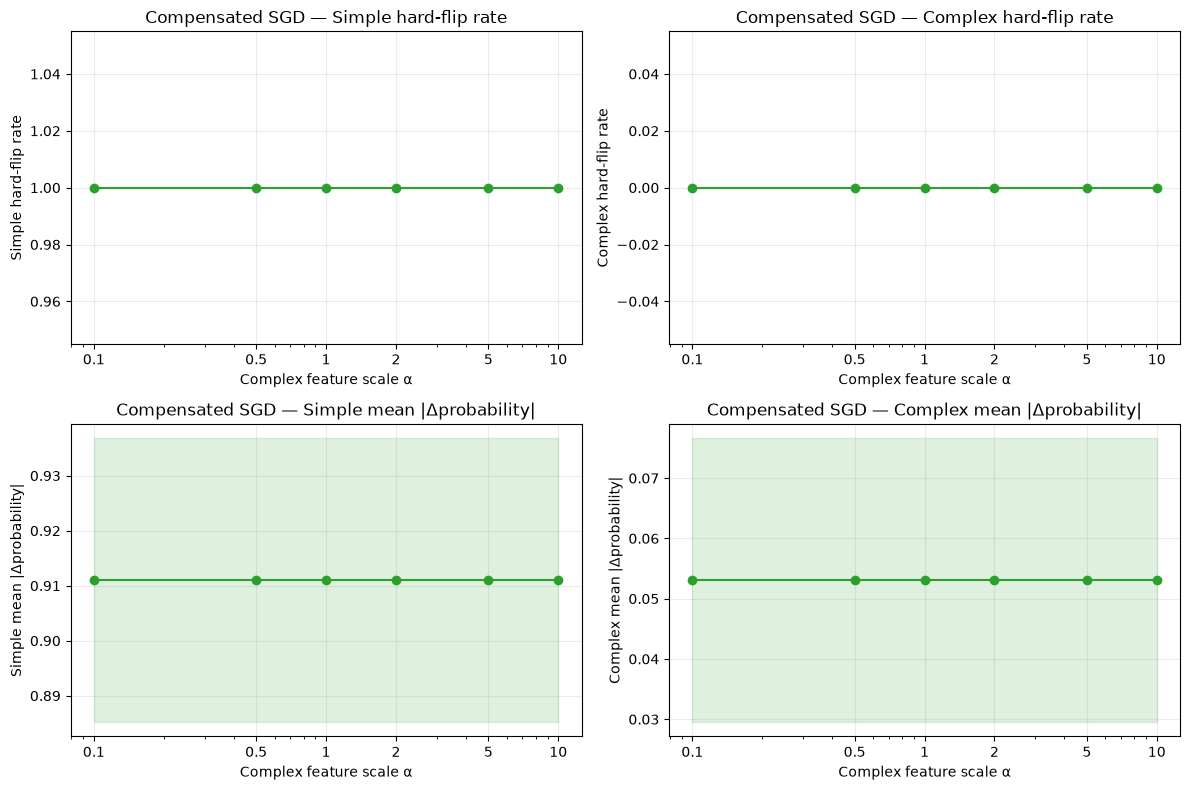

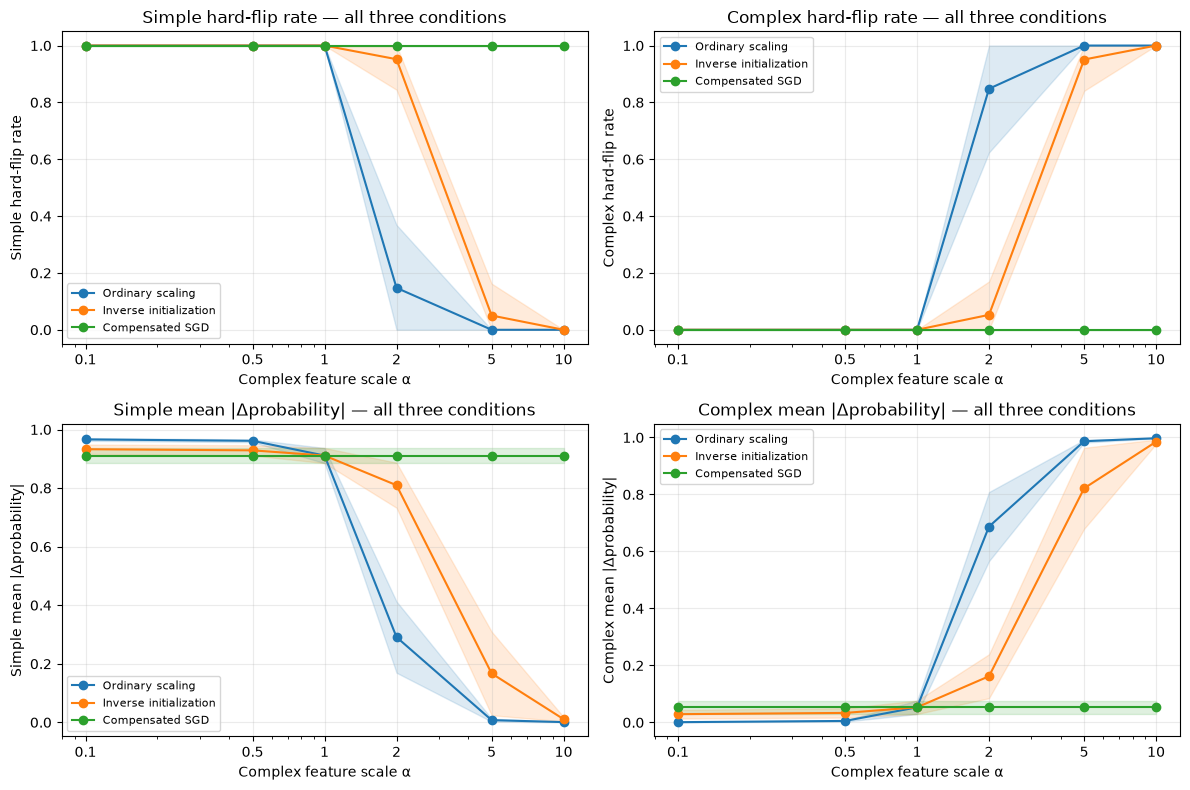

In [10]:
flip_metrics = [
    ('simple_flip_rate', 'Simple hard-flip rate'),
    ('complex_flip_rate', 'Complex hard-flip rate'),
    ('simple_probability_change', 'Simple mean |Δprobability|'),
    ('complex_probability_change', 'Complex mean |Δprobability|'),
]
missing = [col for col, _ in flip_metrics if col not in final.columns]
if missing:
    print('Counterfactual metrics not found in existing CSVs:', missing)
    print('Run: python run_all_experiments.py')
else:
    for condition in conditions:
        fig, axes = plt.subplots(2, 2, figsize=(12, 8))
        for ax, (col, label) in zip(axes.flat, flip_metrics):
            mean_sd_plot(ax, final, col, condition=condition)
            ax.set_title(f'{LABELS[condition]} — {label}')
            ax.set_ylabel(label)
        fig.tight_layout()
        finish(f'{condition}_counterfactual_metrics')

    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    for ax, (col, label) in zip(axes.flat, flip_metrics):
        for condition in conditions:
            mean_sd_plot(ax, final, col, condition=condition)
        ax.legend(fontsize=8)
        ax.set_title(label + ' — all three conditions')
        ax.set_ylabel(label)
    fig.tight_layout()
    finish('combined_counterfactual_metrics')


## 11. Tabular research summary and export

The CSV below summarizes mean and standard deviation across seeds. It can be used to draft a findings section without copying values manually. It is separate from the original experiment output; the source CSV files are never modified.

In [11]:
summary = (final.groupby(['experiment', 'alpha'])
           .agg(seeds=('seed', 'nunique'),
                reliance_mean=('complex_reliance', 'mean'),
                reliance_sd=('complex_reliance', 'std'),
                loss_mean=('loss', 'mean'),
                loss_sd=('loss', 'std'),
                accuracy_mean=('accuracy', 'mean'))
           .reset_index())
print(summary.round(5).to_string(index=False))
output = ROOT / 'results' / 'aggregated_research_summary.csv'
summary.to_csv(output, index=False)
print('\nSaved:', output)
print('Saved figures:', FIGURES.resolve())

     experiment  alpha  seeds  reliance_mean  reliance_sd  loss_mean  loss_sd  accuracy_mean
compensated_sgd    0.1      5           0.00      0.00000    0.01826  0.00273            1.0
compensated_sgd    0.5      5           0.00      0.00000    0.01826  0.00273            1.0
compensated_sgd    1.0      5           0.00      0.00000    0.01826  0.00273            1.0
compensated_sgd    2.0      5           0.00      0.00000    0.01826  0.00273            1.0
compensated_sgd    5.0      5           0.00      0.00000    0.01826  0.00273            1.0
compensated_sgd   10.0      5           0.00      0.00000    0.01826  0.00273            1.0
   inverse_init    0.1      5           0.00      0.00000    0.01974  0.00316            1.0
   inverse_init    0.5      5           0.00      0.00000    0.01931  0.00303            1.0
   inverse_init    1.0      5           0.00      0.00000    0.01826  0.00273            1.0
   inverse_init    2.0      5           0.05      0.11180    0.01441  

## 12. Interpretation checklist

- **Ordinary scaling:** Does conflict reliance rise as alpha increases?
- **Inverse initialization:** Does the effect remain even though initial logits match? If so, changed initial functions are not necessary for the effect.
- **Compensated SGD:** Do final logits stay close to the alpha=1 reference? If so, the optimization-scaling mechanism is consistent with the observed behavior.
- **Accuracy versus reliance:** Can all models have 100% accuracy while following different rules on conflict probes?
- **Caution:** Conflict probes are out-of-distribution, the synthetic distribution has only four prototypes, and five seeds are a limited sample. Do not interpret these graphs as universal evidence of neural-network simplicity bias.

**Outputs:** Individual and combined PNG plots in `results/figures/`, plus `results/aggregated_research_summary.csv`.